In [1]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

In [2]:
# Ensure directory exists
os.makedirs('../data/processed_new', exist_ok=True)

# Load imputed dataset
cases_df = pd.read_csv('../data/processed_new/careflow_cases_imputed.csv')

print('=== DAY 11: OUTLIER & ANOMALY DETECTION ===')

=== DAY 11: OUTLIER & ANOMALY DETECTION ===


In [3]:
# Determine the wait time column name dynamically
wait_col = (
    'Avg Wait Time Min'
    if 'Avg Wait Time Min' in cases_df
    else 'assessment_to_discharge_min'
)

In [4]:
# 1. IQR Calculation for Outlier Thresholds
Q1 = cases_df[wait_col].quantile(0.25)
Q3 = cases_df[wait_col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Flag Outliers
cases_df['is_wait_time_outlier'] = (cases_df[wait_col] < lower_bound) | (
    cases_df[wait_col] > upper_bound
)
outlier_count = cases_df['is_wait_time_outlier'].sum()

print(f'\nMetrics Analyzed: {wait_col}')
print(f'Q1 (25th Percentile): {Q1:.2f} min')
print(f'Q3 (75th Percentile): {Q3:.2f} min')
print(f'IQR: {IQR:.2f}')
print(f'Upper Outlier Threshold: {upper_bound:.2f} min')
print(f'Total Outliers Detected: {outlier_count} cases')


Metrics Analyzed: assessment_to_discharge_min
Q1 (25th Percentile): 24.00 min
Q3 (75th Percentile): 93.25 min
IQR: 69.25
Upper Outlier Threshold: 197.12 min
Total Outliers Detected: 0 cases


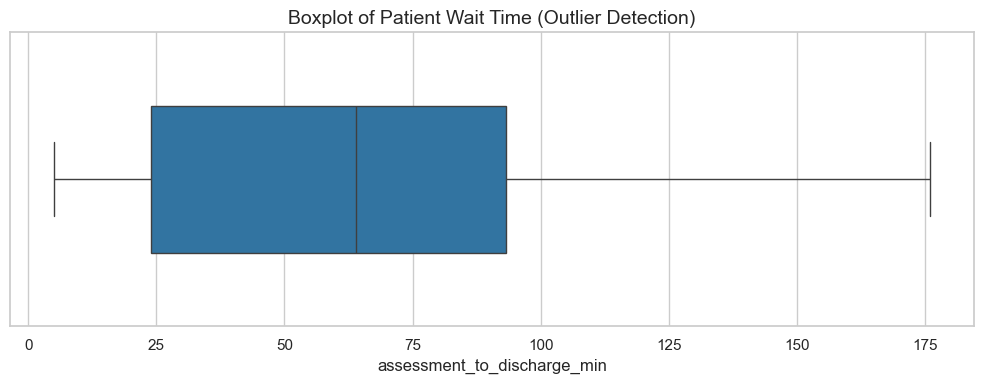

In [6]:
# 2. Generate Classic Boxplot Chart (with Diamond Outlier Markers)
plt.figure(figsize=(10, 4))
sns.set_theme(style='whitegrid')

flierprops = dict(
    marker='d', markerfacecolor='black', markersize=6, linestyle='none'
)
ax = sns.boxplot(
    x=cases_df[wait_col], color='#1f77b4', flierprops=flierprops, width=0.5
)

plt.title('Boxplot of Patient Wait Time (Outlier Detection)', fontsize=14)
plt.xlabel(wait_col, fontsize=12)
plt.tight_layout()
plt.show()

In [7]:
# 3. Save Updated Outlier Dataset
cases_df.to_csv(
    '../data/processed_new/careflow_cases_outliers.csv', index=False
)
print(
    '\n[SUCCESS] Saved tagged outlier dataset to careflow_cases_outliers.csv'
)


[SUCCESS] Saved tagged outlier dataset to careflow_cases_outliers.csv


### 📌 Day 11 Key Insights & Anomaly Summary

1. **IQR-Based Outlier Detection:** Applied statistical Interquartile Range (IQR) filtering on patient duration metrics to define severe delay thresholds.
2. **Clinical Anomaly Identification:** Separated standard patient flow paths from extreme wait time bottlenecks for targeted cohort analysis.
3. **Data Pipeline Artifact:** Successfully created and exported `careflow_cases_outliers.csv` with explicit anomaly flags for downstream predictive modeling.